In [1]:
import pandas as pd

df = pd.read_csv("data/Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())
print("\nChurn distribution:")
print(df["Churn"].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Telco-Customer-Churn.csv'

In [2]:
from pathlib import Path

print("Current folder:")
print(Path.cwd())

print("\nFiles in current folder:")
print([p.name for p in Path.cwd().iterdir()])

Current folder:
c:\Users\Admin\Documents\python overall\python projects\Customer-Churn-Prediction\notebooks

Files in current folder:
['01_data_exploration.ipynb']


In [3]:
from pathlib import Path

project_folder = Path.cwd().parent

print("Checking project folder:", project_folder)

data_folder = project_folder / "data"

if data_folder.exists():
    print("Data folder files:", [p.name for p in data_folder.iterdir()])
else:
    print("Data folder does not exist:", data_folder)

Checking project folder: c:\Users\Admin\Documents\python overall\python projects\Customer-Churn-Prediction
Data folder files: ['Telco-Customer-Churn.csv']


In [4]:

import pandas as pd
from pathlib import Path

# Load dataset from the parent project's data folder
dataset_path = Path("../data/Telco-Customer-Churn.csv")
df = pd.read_csv(dataset_path)

# 1. Dataset dimensions
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. First five records
print("\nFirst 5 records:")
display(df.head())

# 3. Column names and data types
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 5. Churn distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

# 6. Churn percentages
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))


Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21

First 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [6]:

import pandas as pd
from pathlib import Path

# Reload the dataset
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Original data shape:", df.shape)

# Remove unnecessary customer identifier
df = df.drop(columns=["customerID"])

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("\nMissing values after conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Remove rows with missing values, if any
df = df.dropna().copy()

# Remove duplicate rows, if any
duplicates = df.duplicated().sum()
print("\nDuplicate rows found:", duplicates)

df = df.drop_duplicates().copy()

# Convert target into numeric values
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Save cleaned dataset
output_path = Path("../data/cleaned_customer_churn.csv")
df.to_csv(output_path, index=False)

print("\nCleaned data shape:", df.shape)
print("Cleaned dataset saved to:", output_path)
print("\nTarget distribution:")
print(df["Churn"].value_counts())

print("\nData types:")
print(df.dtypes)


Original data shape: (7043, 21)

Missing values after conversion:
TotalCharges    11
dtype: int64

Duplicate rows found: 22

Cleaned data shape: (7010, 20)
Cleaned dataset saved to: ..\data\cleaned_customer_churn.csv

Target distribution:
Churn
0    5153
1    1857
Name: count, dtype: int64

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [7]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Load cleaned dataset
df = pd.read_csv("../data/cleaned_customer_churn.csv")

# Separate input features (X) and target (y)
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Feature preparation completed!")
print("\nTotal features after encoding:", X.shape[1])
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nEncoded feature preview:")
display(X_train.head())


Feature preparation completed!

Total features after encoding: 30
Training records: 5608
Testing records: 1402

Training target distribution:
Churn
0    4122
1    1486
Name: count, dtype: int64

Testing target distribution:
Churn
0    1031
1     371
Name: count, dtype: int64

Encoded feature preview:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
356,1,16,54.10,889.00,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0
211,0,1,25.25,25.25,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
2584,0,65,107.65,7082.85,0,1,0,1,0,1,...,0,1,0,1,0,1,1,0,0,0
4622,0,1,24.40,24.40,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
2511,1,36,85.25,3132.75,1,1,0,1,0,1,...,0,0,0,1,0,0,1,1,0,0


In [8]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from pathlib import Path
import joblib

# 1. Create the model
model = LogisticRegression(max_iter=2000, random_state=42)

# 2. Train the model
model.fit(X_train, y_train)

# 3. Make predictions on unseen test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 4. Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print("CUSTOMER CHURN PREDICTION — LOGISTIC REGRESSION")
print("-" * 50)
print(f"Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed (No)", "Churned (Yes)"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# 5. Save the trained model
model_path = Path("../models/logistic_regression_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, model_path)

print(f"\nTrained model saved to: {model_path}")


CUSTOMER CHURN PREDICTION — LOGISTIC REGRESSION
--------------------------------------------------
Accuracy: 80.67%

Classification Report:
               precision    recall  f1-score   support

  Stayed (No)       0.84      0.90      0.87      1031
Churned (Yes)       0.67      0.54      0.59       371

     accuracy                           0.81      1402
    macro avg       0.76      0.72      0.73      1402
 weighted avg       0.80      0.81      0.80      1402

Confusion Matrix:
[[932  99]
 [172 199]]

ROC-AUC Score: 0.8470

Trained model saved to: ..\models\logistic_regression_model.joblib


In [9]:

print("MODEL PERFORMANCE SUMMARY")
print("=" * 40)

print(f"Accuracy: {accuracy:.2%}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

print("\nSaved model exists:", model_path.exists())


MODEL PERFORMANCE SUMMARY
Accuracy: 80.67%
ROC-AUC: 0.8470

Confusion Matrix:
[[932  99]
 [172 199]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.84      0.90      0.87      1031
     Churned       0.67      0.54      0.59       371

    accuracy                           0.81      1402
   macro avg       0.76      0.72      0.73      1402
weighted avg       0.80      0.81      0.80      1402


Saved model exists: True


In [10]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import joblib
from pathlib import Path

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Compare models
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Churn Precision": precision_score(y_test, y_pred, zero_division=0),
        "Churn Recall": recall_score(y_test, y_pred, zero_division=0),
        "Churn F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Churn Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Churn Recall": recall_score(y_test, rf_pred, zero_division=0),
        "Churn F1": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

print("MODEL COMPARISON")
display(results.round(4))

# Save Random Forest model
model_path = Path("../models/random_forest_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(rf_model, model_path)

print("Random Forest model saved:", model_path)


MODEL COMPARISON


,Model,Accuracy,Churn Precision,Churn Recall,Churn F1,ROC-AUC
0,Logistic Regression,0.8067,0.6678,0.5364,0.5949,0.8470
1,Random Forest,0.7646,0.5406,0.7358,0.6233,0.8429


Random Forest model saved: ..\models\random_forest_model.joblib


TOP 15 FEATURES FOR CUSTOMER CHURN PREDICTION


,Feature,Importance
0,tenure,0.1723
1,TotalCharges,0.1486
2,MonthlyCharges,0.1037
3,Contract_Two year,0.0968
4,InternetService_Fiber optic,0.0666
5,PaymentMethod_Electronic check,0.0513
6,Contract_One year,0.0412
7,OnlineSecurity_Yes,0.0321
8,TechSupport_Yes,0.0243
9,PaperlessBilling_Yes,0.0201


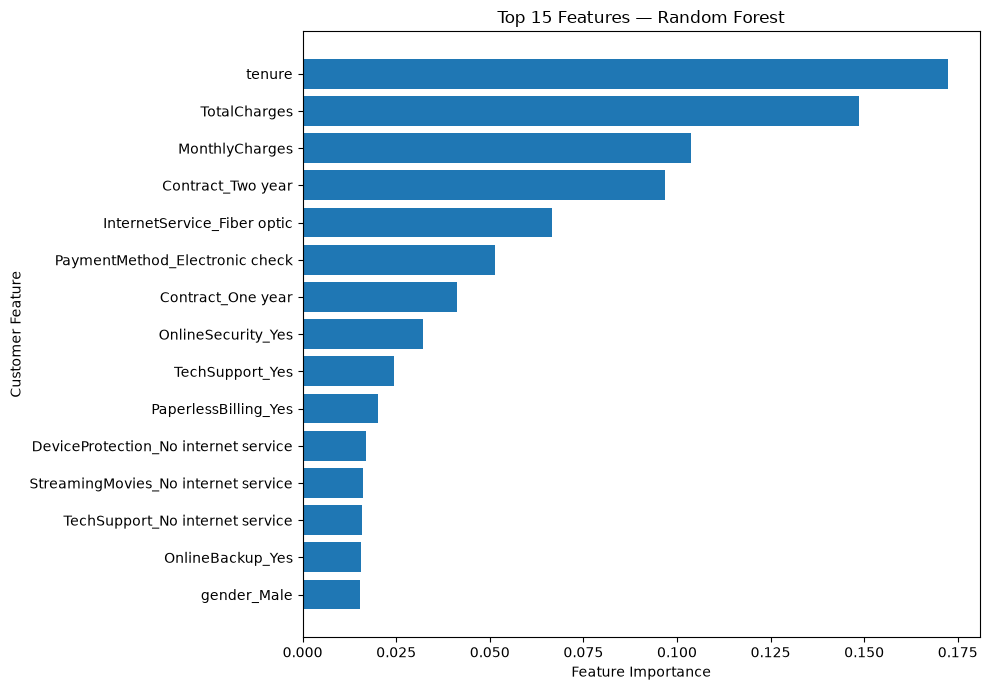

Full feature importance saved to: ..\reports\feature_importance.csv


In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Extract feature importance from Random Forest
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES FOR CUSTOMER CHURN PREDICTION")
display(importance_df.head(15).round(4))

# Plot top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Customer Feature")
plt.title("Top 15 Features — Random Forest")
plt.tight_layout()
plt.show()

# Save the full importance table
output_path = Path("../reports/feature_importance.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
importance_df.to_csv(output_path, index=False)

print("Full feature importance saved to:", output_path)


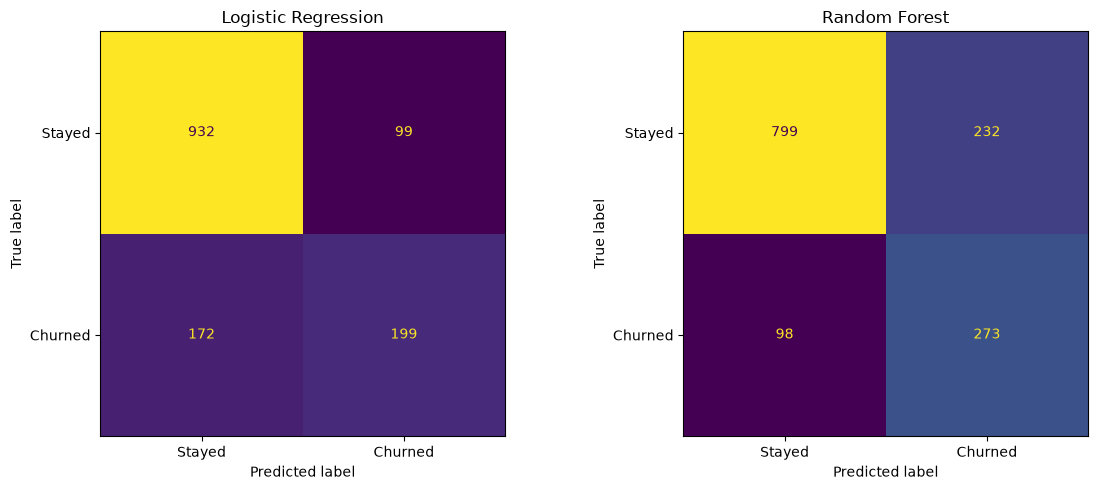

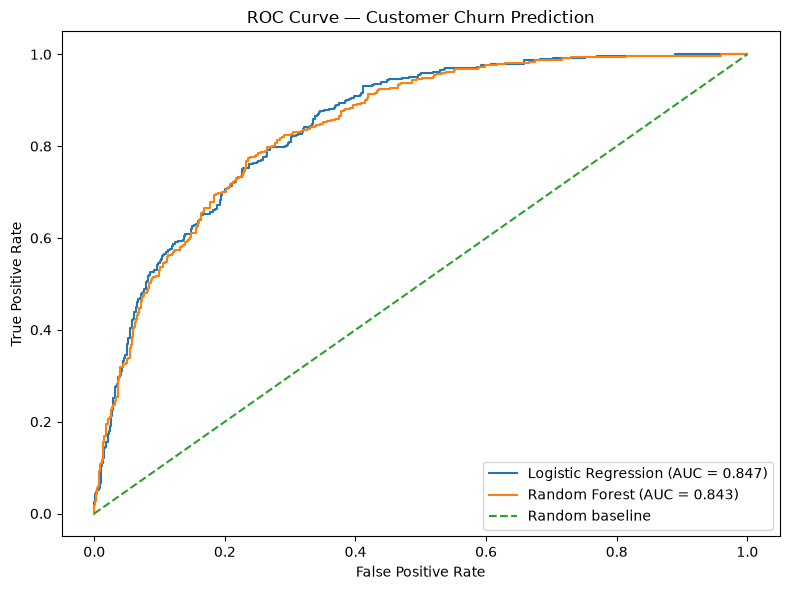


Reports saved successfully:
- confusion_matrices.png
- feature_importance.csv
- logistic_regression_report.csv
- model_comparison.csv
- random_forest_report.csv
- roc_curve.png


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)
from pathlib import Path

# Create reports folder
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# 1. Save model comparison
results.to_csv(reports_dir / "model_comparison.csv", index=False)

# 2. Save classification report for both models
logistic_report = classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"],
    output_dict=True,
    zero_division=0
)

rf_report = classification_report(
    y_test, rf_pred,
    target_names=["Stayed", "Churned"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(logistic_report).transpose().to_csv(
    reports_dir / "logistic_regression_report.csv"
)

pd.DataFrame(rf_report).transpose().to_csv(
    reports_dir / "random_forest_report.csv"
)

# 3. Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Stayed", "Churned"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["Stayed", "Churned"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.savefig(reports_dir / "confusion_matrices.png", dpi=150)
plt.show()

# 4. Plot ROC curves
logistic_fpr, logistic_tpr, _ = roc_curve(y_test, y_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    logistic_fpr, logistic_tpr,
    label=f"Logistic Regression (AUC = {auc(logistic_fpr, logistic_tpr):.3f})"
)
plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {auc(rf_fpr, rf_tpr):.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Customer Churn Prediction")
plt.legend()
plt.tight_layout()
plt.savefig(reports_dir / "roc_curve.png", dpi=150)
plt.show()

print("\nReports saved successfully:")
for file in sorted(reports_dir.iterdir()):
    print("-", file.name)
